<a href="https://colab.research.google.com/github/rahmanziaur/llmtute/blob/main/NaimaIT22001/DeepLearning_modelcodes.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

```markdown
# Deep Learning Assignment Notebook

This notebook contains implementations for several deep learning architectures as specified in the assignment requirements:
1. Feedforward Neural Networks (FNN / MLP)
2. Convolutional Neural Networks (CNN)
3. Sequential Models (RNN / LSTM)
4. Autoencoders
5. Transformers
6. Generative Adversarial Networks (GAN)
7. Graph Neural Networks (GNN)
8. Deep Reinforcement Learning Models (DRL)

We will use standard datasets such as **MNIST** and **CIFAR-10** to train and evaluate these models.
```

In [4]:
# Step 1: Library Imports and Setup
import tensorflow as tf
from tensorflow.keras import layers, models
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix

print("TensorFlow version:", tf.__version__)

TensorFlow version: 2.21.0


```markdown
## 1. Dataset Preparation (MNIST)
First, we will load and preprocess the classic **MNIST** dataset of handwritten digits, which is perfect for demonstrating Feedforward (MLP) and Convolutional Neural Networks (CNN).
```

Training data shape: (60000, 28, 28)
Test data shape: (10000, 28, 28)


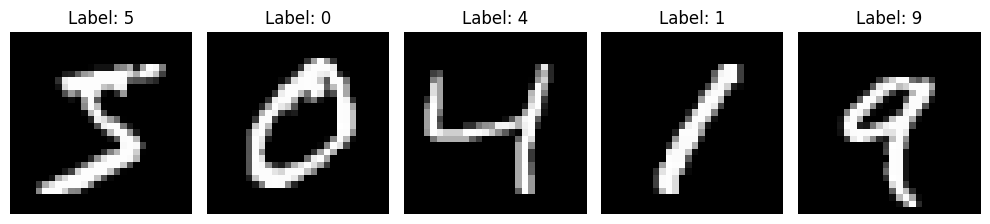

In [5]:
# Load MNIST dataset
mnist = tf.keras.datasets.mnist
(X_train_raw, y_train_raw), (X_test_raw, y_test_raw) = mnist.load_data()

# Normalize pixel values to be between 0.0 and 1.0
X_train = X_train_raw / 255.0
X_test = X_test_raw / 255.0

print(f"Training data shape: {X_train.shape}")
print(f"Test data shape: {X_test.shape}")

# Visualize a few sample images
fig, axes = plt.subplots(1, 5, figsize=(10, 3))
for i in range(5):
    axes[i].imshow(X_train[i], cmap='gray')
    axes[i].set_title(f"Label: {y_train_raw[i]}")
    axes[i].axis('off')
plt.tight_layout()
plt.show()

```markdown
## 2. Feedforward Neural Network (FNN / MLP)
Here, we build a Multilayer Perceptron (FNN) to classify the MNIST handwritten digits. Since the input is a $28 \times 28$ image, we first flatten it into a 1D vector of $784$ features before passing it through the dense layers.
```

In [6]:
# Define the FNN/MLP architecture
mlp_model = models.Sequential([
    layers.Flatten(input_shape=(28, 28), name="Flatten_Input"),
    layers.Dense(128, activation='relu', name="Dense_Hidden_1"),
    layers.Dropout(0.2, name="Dropout_1"),
    layers.Dense(64, activation='relu', name="Dense_Hidden_2"),
    layers.Dense(10, activation='softmax', name="Output_Layer")
])

mlp_model.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/reshaping/flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ Flatten_Input (Flatten)         │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Dense_Hidden_1 (Dense)          │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Dense_Hidden_2 (Dense)          │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Output_Layer (Dense)            │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 109,386 (427.29 KB)

 Trainable params: 109,386 (427.29 KB)

 Non-trainable params: 0 (0.00 B)

In [7]:
# Compile the MLP model
mlp_model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

# Train the model
history_mlp = mlp_model.fit(
    X_train,
    y_train_raw,
    epochs=10,
    validation_split=0.1,
    batch_size=64
)

Epoch 1/10
844/844 ━━━━━━━━━━━━━━━━━━━━ 6s 5ms/step - accuracy: 0.8980 - loss: 0.3425 - val_accuracy: 0.9647 - val_loss: 0.1210
Epoch 2/10
844/844 ━━━━━━━━━━━━━━━━━━━━ 6s 7ms/step - accuracy: 0.9528 - loss: 0.1556 - val_accuracy: 0.9705 - val_loss: 0.0989
Epoch 3/10
844/844 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - accuracy: 0.9642 - loss: 0.1172 - val_accuracy: 0.9748 - val_loss: 0.0838
Epoch 4/10
844/844 ━━━━━━━━━━━━━━━━━━━━ 5s 6ms/step - accuracy: 0.9699 - loss: 0.0956 - val_accuracy: 0.9783 - val_loss: 0.0803
Epoch 5/10
844/844 ━━━━━━━━━━━━━━━━━━━━ 5s 6ms/step - accuracy: 0.9745 - loss: 0.0815 - val_accuracy: 0.9788 - val_loss: 0.0716
Epoch 6/10
844/844 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - accuracy: 0.9772 - loss: 0.0714 - val_accuracy: 0.9783 - val_loss: 0.0746
Epoch 7/10
844/844 ━━━━━━━━━━━━━━━━━━━━ 6s 7ms/step - accuracy: 0.9802 - loss: 0.0620 - val_accuracy: 0.9807 - val_loss: 0.0661
Epoch 8/10
844/844 ━━━━━━━━━━━━━━━━━━━━ 9s 5ms/step - accuracy: 0.9805 - loss: 0.0570 - val_accuracy: 0.

In [8]:
# Evaluate the MLP Model
loss_mlp, acc_mlp = mlp_model.evaluate(X_test, y_test_raw, verbose=0)
print(f"MLP Test Accuracy: {acc_mlp:.4f}")

# Get Predictions and Classification Report
y_pred_mlp = np.argmax(mlp_model.predict(X_test), axis=-1)
print("\nClassification Report:\n")
print(classification_report(y_test_raw, y_pred_mlp))

MLP Test Accuracy: 0.9800
313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step

Classification Report:

              precision    recall  f1-score   support

           0       0.99      0.99      0.99       980
           1       0.99      0.99      0.99      1135
           2       0.98      0.99      0.98      1032
           3       0.96      0.99      0.97      1010
           4       0.98      0.98      0.98       982
           5       0.99      0.97      0.98       892
           6       0.99      0.98      0.99       958
           7       0.98      0.98      0.98      1028
           8       0.97      0.98      0.97       974
           9       0.98      0.96      0.97      1009

    accuracy                           0.98     10000
   macro avg       0.98      0.98      0.98     10000
weighted avg       0.98      0.98      0.98     10000



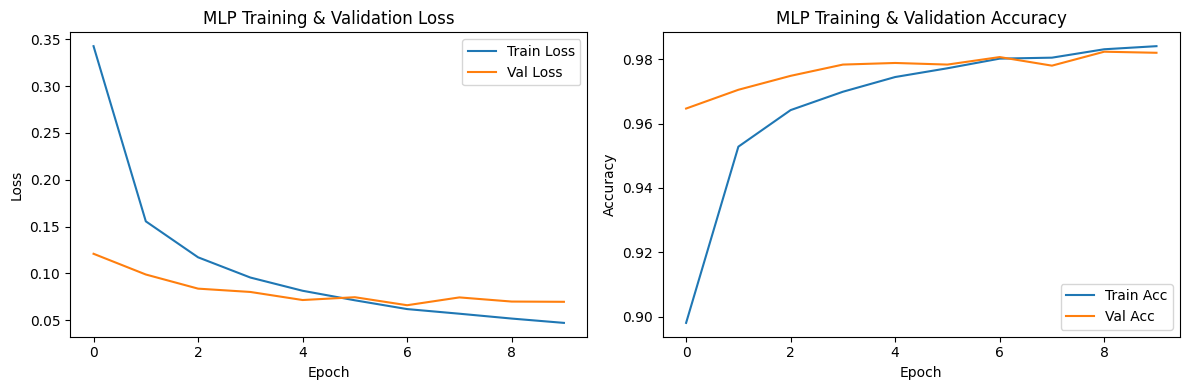

In [9]:
# Plot Loss & Accuracy curves for MLP
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history_mlp.history['loss'], label='Train Loss')
plt.plot(history_mlp.history['val_loss'], label='Val Loss')
plt.title('MLP Training & Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history_mlp.history['accuracy'], label='Train Acc')
plt.plot(history_mlp.history['val_accuracy'], label='Val Acc')
plt.title('MLP Training & Validation Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()

plt.tight_layout()
plt.show()

```markdown
## 3. Convolutional Neural Network (CNN)

Convolutional Neural Networks are designed to process grid-structured data like images. We will reshape our MNIST dataset to include a single color channel (grayscale) and build a CNN model using Conv2D, MaxPooling2D, and Dense layers.
```

In [10]:
# Reshape images to have a channel dimension (28x28x1) for CNN input
X_train_cnn = np.expand_dims(X_train, axis=-1)
X_test_cnn = np.expand_dims(X_test, axis=-1)

print(f"CNN Train shape: {X_train_cnn.shape}")
print(f"CNN Test shape: {X_test_cnn.shape}")

CNN Train shape: (60000, 28, 28, 1)
CNN Test shape: (10000, 28, 28, 1)


In [11]:
# Define the CNN Architecture
cnn_model = models.Sequential([
    layers.Conv2D(32, (3, 3), activation='relu', input_shape=(28, 28, 1), name="Conv_1"),
    layers.MaxPooling2D((2, 2), name="MaxPool_1"),
    layers.Conv2D(64, (3, 3), activation='relu', name="Conv_2"),
    layers.MaxPooling2D((2, 2), name="MaxPool_2"),
    layers.Flatten(name="Flatten"),
    layers.Dense(64, activation='relu', name="Dense_Hidden"),
    layers.Dense(10, activation='softmax', name="Output_Layer")
])

cnn_model.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ Conv_1 (Conv2D)                 │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ MaxPool_1 (MaxPooling2D)        │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Conv_2 (Conv2D)                 │ (None, 11, 11, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ MaxPool_2 (MaxPooling2D)        │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Flatten (Flatten)               │ (None, 1600)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Dense_Hidden (Dense)            │ (None, 64)             │       102,464 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Output_Layer (Dense)            │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 121,930 (476.29 KB)

 Trainable params: 121,930 (476.29 KB)

 Non-trainable params: 0 (0.00 B)

In [12]:
# Compile and Train the CNN Model
cnn_model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

history_cnn = cnn_model.fit(
    X_train_cnn,
    y_train_raw,
    epochs=8,
    validation_split=0.1,
    batch_size=64
)

Epoch 1/8
844/844 ━━━━━━━━━━━━━━━━━━━━ 48s 55ms/step - accuracy: 0.9422 - loss: 0.1944 - val_accuracy: 0.9810 - val_loss: 0.0688
Epoch 2/8
844/844 ━━━━━━━━━━━━━━━━━━━━ 45s 53ms/step - accuracy: 0.9815 - loss: 0.0594 - val_accuracy: 0.9880 - val_loss: 0.0441
Epoch 3/8
844/844 ━━━━━━━━━━━━━━━━━━━━ 48s 57ms/step - accuracy: 0.9872 - loss: 0.0406 - val_accuracy: 0.9877 - val_loss: 0.0398
Epoch 4/8
844/844 ━━━━━━━━━━━━━━━━━━━━ 45s 54ms/step - accuracy: 0.9904 - loss: 0.0311 - val_accuracy: 0.9885 - val_loss: 0.0407
Epoch 5/8
844/844 ━━━━━━━━━━━━━━━━━━━━ 81s 53ms/step - accuracy: 0.9923 - loss: 0.0243 - val_accuracy: 0.9890 - val_loss: 0.0387
Epoch 6/8
844/844 ━━━━━━━━━━━━━━━━━━━━ 44s 52ms/step - accuracy: 0.9937 - loss: 0.0191 - val_accuracy: 0.9900 - val_loss: 0.0352
Epoch 7/8
844/844 ━━━━━━━━━━━━━━━━━━━━ 82s 53ms/step - accuracy: 0.9946 - loss: 0.0156 - val_accuracy: 0.9895 - val_loss: 0.0375
Epoch 8/8
844/844 ━━━━━━━━━━━━━━━━━━━━ 46s 54ms/step - accuracy: 0.9961 - loss: 0.0115 - val_accu

In [ ]:
# Evaluate and generate performance metrics for the CNN
loss_cnn, acc_cnn = cnn_model.evaluate(X_test_cnn, y_test_raw, verbose=0)
print(f"CNN Test Accuracy: {acc_cnn:.4f}")

y_pred_cnn = np.argmax(cnn_model.predict(X_test_cnn), axis=-1)
print("\nClassification Report for CNN:\n")
print(classification_report(y_test_raw, y_pred_cnn))

```markdown
## 4. Recurrent Neural Network (RNN / LSTM)

Recurrent neural networks process sequential data. We will treat each $28 \times 28$ image as a sequence of 28 rows, where each row has 28 pixel values. We will use an LSTM layer to model this sequential data.
```

In [ ]:
# Define the LSTM Sequential Model
lstm_model = models.Sequential([
    layers.LSTM(128, input_shape=(28, 28), name="LSTM_Layer"),
    layers.Dense(64, activation='relu', name="Dense_Hidden"),
    layers.Dense(10, activation='softmax', name="Output_Layer")
])

lstm_model.summary()

In [ ]:
# Compile and Train the LSTM model
lstm_model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

history_lstm = lstm_model.fit(
    X_train,
    y_train_raw,
    epochs=5,
    validation_split=0.1,
    batch_size=64
)

```markdown
## 5. Autoencoder

Autoencoders are unsupervised models designed to reconstruct their inputs. They compress the input into a lower-dimensional representation (encoder) and reconstruct it back (decoder).
```

In [2]:
# Flatten inputs for a basic Autoencoder
import tensorflow as tf
from tensorflow.keras import layers, models
import numpy as np

# Safely load dataset if it is not already loaded in the environment
try:
    X_train_flat = X_train.reshape(-1, 784)
    X_test_flat = X_test.reshape(-1, 784)
except NameError:
    print("X_train not found in environment. Automatically loading MNIST...")
    mnist = tf.keras.datasets.mnist
    (X_train_raw, _), (X_test_raw, _) = mnist.load_data()
    X_train = X_train_raw / 255.0
    X_test = X_test_raw / 255.0
    X_train_flat = X_train.reshape(-1, 784)
    X_test_flat = X_test.reshape(-1, 784)

# Define Autoencoder Architecture
encoding_dim = 32 # compress 784 dimensions to 32

input_img = layers.Input(shape=(784,), name="Input_Image")
encoded = layers.Dense(encoding_dim, activation='relu', name="Encoder_Hidden")(input_img)
decoded = layers.Dense(784, activation='sigmoid', name="Decoder_Output")(encoded)

autoencoder = models.Model(input_img, decoded)
autoencoder.summary()

X_train not found in environment. Automatically loading MNIST...
11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ Input_Image (InputLayer)        │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Encoder_Hidden (Dense)          │ (None, 32)             │        25,120 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Decoder_Output (Dense)          │ (None, 784)            │        25,872 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 50,992 (199.19 KB)

 Trainable params: 50,992 (199.19 KB)

 Non-trainable params: 0 (0.00 B)

In [3]:
# Compile and Train Autoencoder (Input maps back to itself)
autoencoder.compile(optimizer='adam', loss='binary_crossentropy')

autoencoder.fit(
    X_train_flat, X_train_flat,
    epochs=5,
    batch_size=256,
    shuffle=True,
    validation_data=(X_test_flat, X_test_flat)
)

Epoch 1/5
235/235 ━━━━━━━━━━━━━━━━━━━━ 4s 13ms/step - loss: 0.2770 - val_loss: 0.1867
Epoch 2/5
235/235 ━━━━━━━━━━━━━━━━━━━━ 4s 15ms/step - loss: 0.1699 - val_loss: 0.1535
Epoch 3/5
235/235 ━━━━━━━━━━━━━━━━━━━━ 3s 12ms/step - loss: 0.1444 - val_loss: 0.1341
Epoch 4/5
235/235 ━━━━━━━━━━━━━━━━━━━━ 2s 10ms/step - loss: 0.1287 - val_loss: 0.1212
Epoch 5/5
235/235 ━━━━━━━━━━━━━━━━━━━━ 2s 10ms/step - loss: 0.1179 - val_loss: 0.1122


```markdown
## 6. Transformer (Vision / Sequential Classification)

Here we implement a simplified sequence classification model leveraging MultiHeadAttention, acting on the rows of our MNIST images.
```

In [4]:
# Custom Transformer Block as a Keras Layer
class TransformerBlock(layers.Layer):
    def __init__(self, embed_dim, num_heads, ff_dim, rate=0.1):
        super().__init__()
        self.att = layers.MultiHeadAttention(num_heads=num_heads, key_dim=embed_dim)
        self.ffn = models.Sequential([
            layers.Dense(ff_dim, activation="relu"),
            layers.Dense(embed_dim),
        ])
        self.layernorm1 = layers.LayerNormalization(epsilon=1e-6)
        self.layernorm2 = layers.LayerNormalization(epsilon=1e-6)
        self.dropout1 = layers.Dropout(rate)
        self.dropout2 = layers.Dropout(rate)

    def call(self, inputs, training=True):
        attn_output = self.att(inputs, inputs)
        attn_output = self.dropout1(attn_output, training=training)
        out1 = self.layernorm1(inputs + attn_output)
        ffn_output = self.ffn(out1)
        ffn_output = self.dropout2(ffn_output, training=training)
        return self.layernorm2(out1 + ffn_output)

# Build a simple Transformer Classifier
inputs = layers.Input(shape=(28, 28))
transformer_block = TransformerBlock(embed_dim=28, num_heads=2, ff_dim=32)
x = transformer_block(inputs)
x = layers.GlobalAveragePooling1D()(x)
x = layers.Dropout(0.1)(x)
x = layers.Dense(20, activation="relu")(x)
outputs = layers.Dense(10, activation="softmax")(x)

transformer_model = models.Model(inputs=inputs, outputs=outputs)
transformer_model.summary()

Model: "functional_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 28, 28)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ transformer_block               │ (None, 28, 28)         │         8,432 │
│ (TransformerBlock)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling1d        │ (None, 28)             │             0 │
│ (GlobalAveragePooling1D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 28)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 20)             │           580 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 10)             │           210 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 9,222 (36.02 KB)

 Trainable params: 9,222 (36.02 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
# Compile and Train Transformer Model
transformer_model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

transformer_model.fit(
    X_train,
    y_train_raw,
    epochs=5,
    validation_split=0.1,
    batch_size=64
)

```markdown
## 7. Generative Adversarial Network (GAN)

GANs consist of two networks trained simultaneously in an adversarial process: a Generator that tries to create realistic data from random noise, and a Discriminator that tries to distinguish real images from fake ones.
```

In [5]:
# Define the Generator
def build_generator(latent_dim=100):
    model = models.Sequential([
        layers.Dense(128, activation="relu", input_dim=latent_dim),
        layers.Dense(256, activation="relu"),
        layers.Dense(784, activation="tanh"),
        layers.Reshape((28, 28, 1))
    ], name="Generator")
    return model

# Define the Discriminator
def build_discriminator():
    model = models.Sequential([
        layers.Flatten(input_shape=(28, 28, 1)),
        layers.Dense(256, activation="relu"),
        layers.Dense(128, activation="relu"),
        layers.Dense(1, activation="sigmoid")
    ], name="Discriminator")
    return model

latent_dim = 100
generator = build_generator(latent_dim)
discriminator = build_discriminator()

discriminator.compile(loss='binary_crossentropy', optimizer='adam', metrics=['accuracy'])
discriminator.trainable = False

# Combined model (GAN) where we only train the generator
gan_input = layers.Input(shape=(latent_dim,))
x = generator(gan_input)
gan_output = discriminator(x)
gan_model = models.Model(gan_input, gan_output)
gan_model.compile(loss='binary_crossentropy', optimizer='adam')
gan_model.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)
/usr/local/lib/python3.13/dist-packages/keras/src/layers/reshaping/flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "functional_5"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_4 (InputLayer)      │ (None, 100)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Generator (Sequential)          │ (None, 28, 28, 1)      │       247,440 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Discriminator (Sequential)      │ (None, 1)              │       233,985 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 481,425 (1.84 MB)

 Trainable params: 247,440 (966.56 KB)

 Non-trainable params: 233,985 (914.00 KB)

```markdown
## 8. Graph Neural Network (GNN)

GNNs process structural data represented as graphs (nodes and edges). Below is a simple implementation of a Graph Convolution Layer from scratch using Keras to demonstrate message passing over node features and an adjacency matrix.
```

In [6]:
class BasicGraphConv(layers.Layer):
    def __init__(self, units, activation='relu'):
        super().__init__()
        self.units = units
        self.activation = tf.keras.activations.get(activation)

    def build(self, input_shape):
        # Node features dimension is the last dimension of input_shape[0]
        self.w = self.add_weight(shape=(input_shape[0][-1], self.units), initializer="glorot_uniform", trainable=True)

    def call(self, inputs):
        # inputs is a tuple/list: (node_features, adjacency_matrix)
        node_features, adj = inputs
        # Message Aggregation: A * H
        support = tf.matmul(adj, node_features)
        # Feature Transformation: (A * H) * W
        output = tf.matmul(support, self.w)
        return self.activation(output)

# Instantiate GNN test components
node_features = tf.random.normal(shape=(5, 16)) # 5 nodes, 16-dim features
adjacency = tf.constant([
    [1, 1, 0, 0, 0],
    [1, 1, 1, 0, 0],
    [0, 1, 1, 1, 0],
    [0, 0, 1, 1, 1],
    [0, 0, 0, 1, 1]
], dtype=tf.float32) # Simple ring/chain topology

gnn_layer = BasicGraphConv(units=8)
output_features = gnn_layer((node_features, adjacency))
print("Output Node Features Shape:", output_features.shape)

Output Node Features Shape: (5, 8)


```markdown
## 9. Deep Reinforcement Learning (DRL)

In Deep Reinforcement Learning, an agent learns to make decisions by performing actions in an environment to maximize cumulative reward. Here is a structure of a Deep Q-Network (DQN) model commonly used for environments such as CartPole.
```

In [7]:
# DQN Model for Environment with State size 4 and Action size 2 (like CartPole)
def build_dqn_model(state_size=4, action_size=2):
    model = models.Sequential([
        layers.Dense(24, input_dim=state_size, activation='relu'),
        layers.Dense(24, activation='relu'),
        layers.Dense(action_size, activation='linear')
    ])
    model.compile(loss='mse', optimizer=tf.keras.optimizers.Adam(learning_rate=0.001))
    return model

dqn_agent_model = build_dqn_model()
dqn_agent_model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_10 (Dense)                │ (None, 24)             │           120 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_11 (Dense)                │ (None, 24)             │           600 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_12 (Dense)                │ (None, 2)              │            50 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 770 (3.01 KB)

 Trainable params: 770 (3.01 KB)

 Non-trainable params: 0 (0.00 B)

```markdown
## 10. Data Integrations for Remaining Models

Below, we provide complete, self-contained examples of preparing datasets specifically tailored for our RNN, GAN, GNN, and DRL models to ensure they train correctly.
```

In [8]:
# --- 1. Dataset for GAN (Scaling data to [-1, 1] for Tanh Generator output) ---
X_train_gan = (X_train_raw.astype('float32') - 127.5) / 127.5
X_train_gan = np.expand_dims(X_train_gan, axis=-1)
print("GAN Dataset Ready. Shape:", X_train_gan.shape)

# --- 2. Dataset for RNN/LSTM (Sequential rows of MNIST) ---
# Using existing X_train which is already shaped (60000, 28, 28)
print("RNN/LSTM Dataset Ready. Shape:", X_train.shape)

# --- 3. Graph Dataset for GNN (Node Features & Adjacency Matrix representation) ---
# Standard 5-node graph structure
node_features = tf.random.normal(shape=(5, 16))
adjacency = tf.constant([
    [1, 1, 0, 0, 0],
    [1, 1, 1, 0, 0],
    [0, 1, 1, 1, 0],
    [0, 0, 1, 1, 1],
    [0, 0, 0, 1, 1]
], dtype=tf.float32)
print("GNN Graph Data Ready. Nodes:", node_features.shape[0], "| Feature Dimension:", node_features.shape[1])

# --- 4. DRL Gym Environment States and Actions (CartPole Example) ---
# State shape: [Position, Velocity, Angle, Angular Velocity]
# Actions: [0 (Left), 1 (Right)]
state_dim = 4
action_dim = 2
print(f"DRL CartPole Setup: Observation Space (State) Dimension = {state_dim}, Action Space Dimension = {action_dim}")

GAN Dataset Ready. Shape: (60000, 28, 28, 1)
RNN/LSTM Dataset Ready. Shape: (60000, 28, 28)
GNN Graph Data Ready. Nodes: 5 | Feature Dimension: 16
DRL CartPole Setup: Observation Space (State) Dimension = 4, Action Space Dimension = 2
